Для начала воспроизведем модель из 9 лабораторной работы

Загружено 1920 изображений.


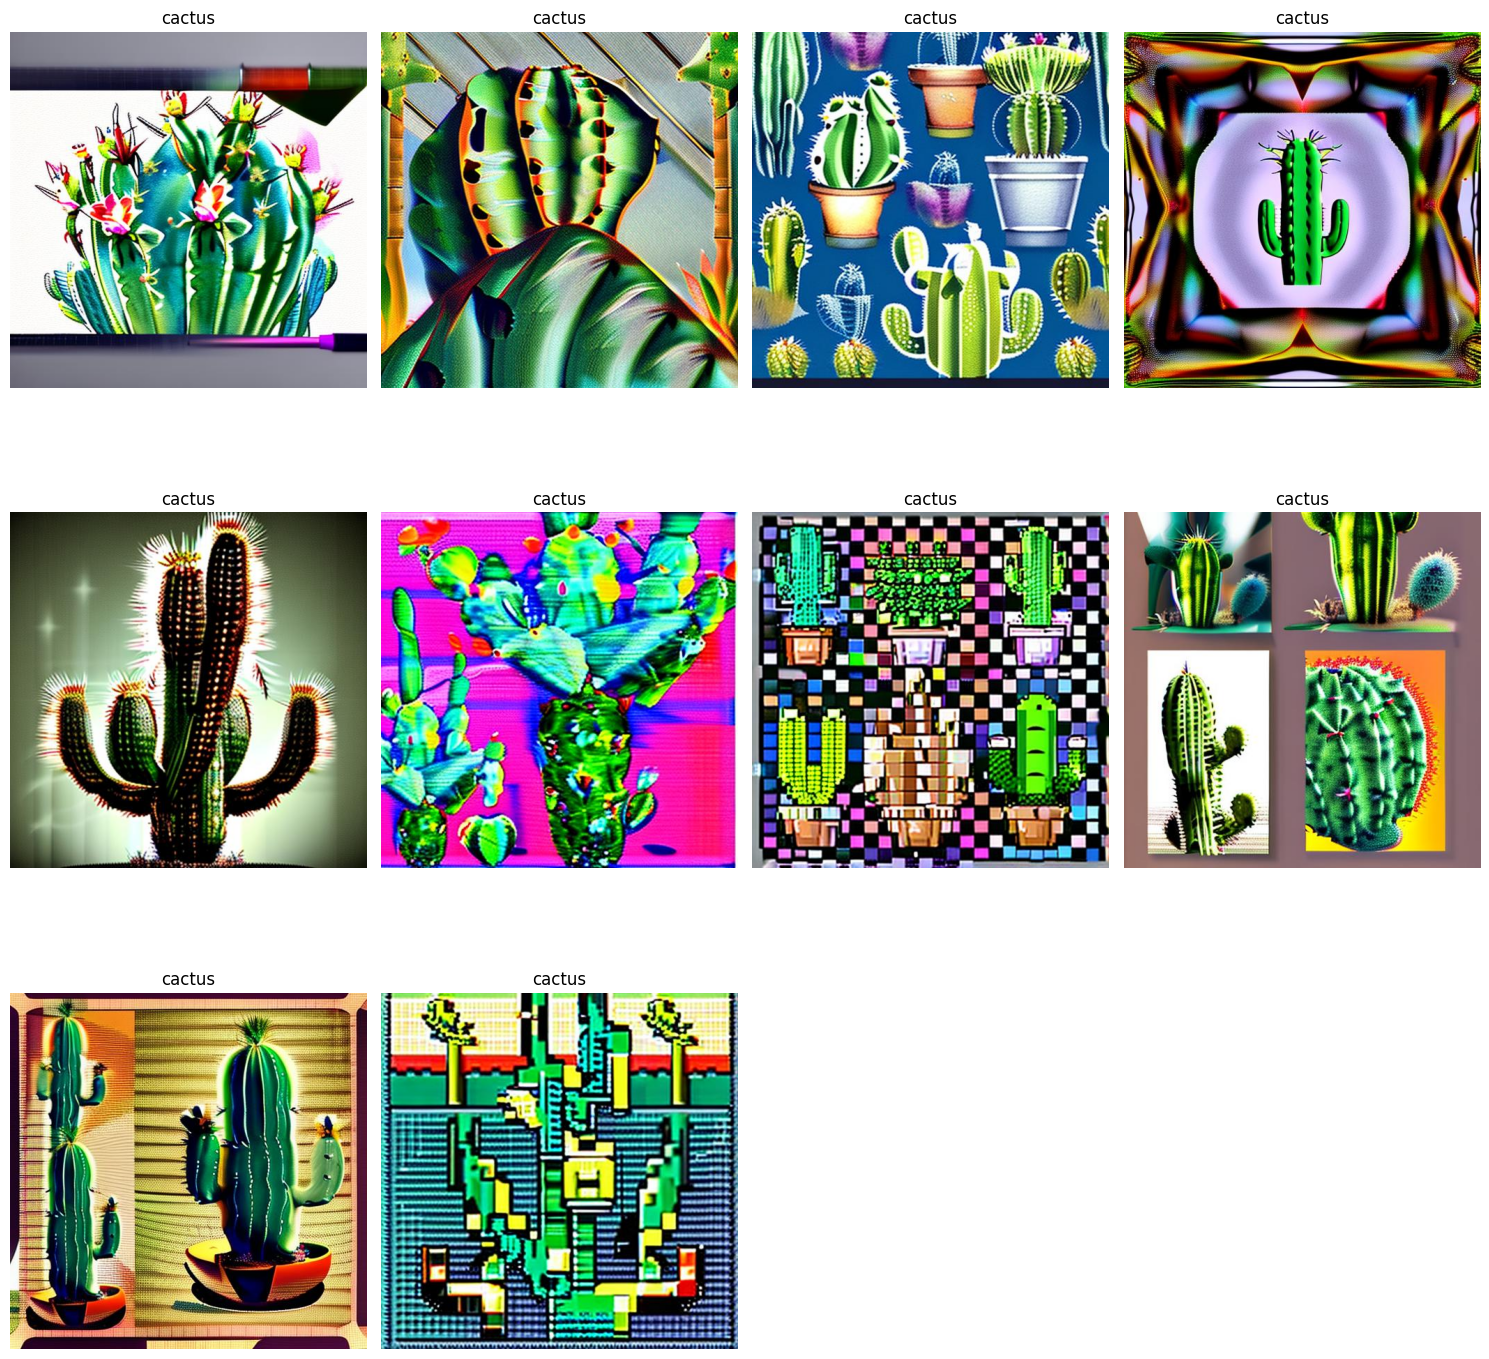


Информация о первом изображении:
Размер: 512x512
Каналы: 3
Тип данных: uint8
Диапазон значений: 0-255


In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

def load_images_from_folder(folder, target_size=(512, 512), allowed_labels=None):
    images = []
    labels = []
    
    if allowed_labels is None:
        allowed_labels = ['cactus', 'fern', 'rose', 'sunflower', 'tulip']
    
    for label in os.listdir(folder):
        if label in allowed_labels:
            label_folder = os.path.join(folder, label)
            if os.path.isdir(label_folder):
                for filename in os.listdir(label_folder):
                    img_path = os.path.join(label_folder, filename)
                    img = cv2.imread(img_path)
                    if img is not None:
                        # Изменяем размер изображения с сохранением пропорций
                        img_resized = cv2.resize(img, target_size, interpolation=cv2.INTER_AREA)
                        images.append(img_resized)
                        labels.append(label)
                    else:
                        print(f"Ошибка загрузки изображения: {img_path}")
                    
    return images, labels

def display_images(images, labels, max_images=10):
    if not images:
        print("Нет изображений для отображения.")
        return
    
    count = min(max_images, len(images))
    cols = 4
    rows = (count + cols - 1) // cols

    plt.figure(figsize=(15, 5 * rows))
    for i in range(count):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        plt.title(labels[i])  # Отображаем метку изображения
        plt.axis('off')
    plt.tight_layout()
    plt.show()

folder_path = "..\\static\\csv\\dataset"

# Загружаем изображения и метки
images, labels = load_images_from_folder(folder_path)

print(f"Загружено {len(images)} изображений.")

# Отображаем загруженные изображения
display_images(images, labels)

# Дополнительная информация о первых загруженных изображениях
if images:
    sample = images[0]
    print(f"\nИнформация о первом изображении:")
    print(f"Размер: {sample.shape[1]}x{sample.shape[0]}")
    print(f"Каналы: {sample.shape[2] if len(sample.shape) > 2 else 1}")
    print(f"Тип данных: {sample.dtype}")
    print(f"Диапазон значений: {np.min(sample)}-{np.max(sample)}")

# Преобразование в массивы
images_array = np.array(images)
labels_array = np.array(labels)

Совершим предобработку изображений

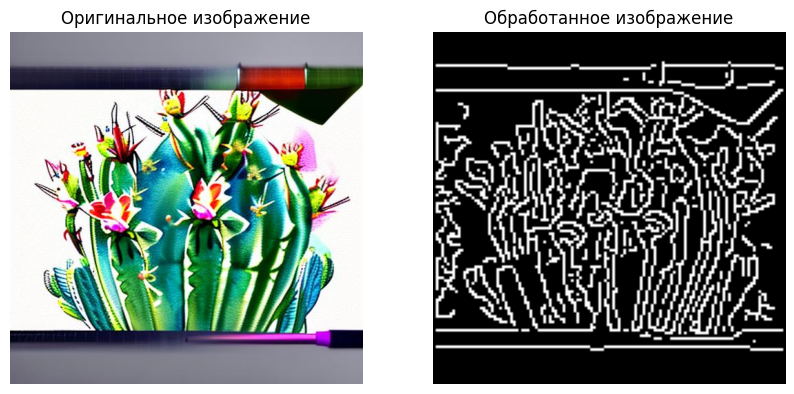

In [20]:
from skimage import color, exposure, feature, filters, measure, morphology
from sklearn.cluster import KMeans
from skimage.feature import canny
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Функция для предварительной обработки изображений
def preprocess_images(images, target_size=(128, 128)):
    processed_images = []
    resized_images = []
    normalized_images = []
    hist_images = []
    binary_images = []
    segmented_kmeans_images = []
    masked_objects_images = []

    for image in images:
        # Изменение размера изображения
        resized_image = cv2.resize(image, target_size, interpolation=cv2.INTER_AREA)
        resized_images.append(resized_image)

        # Преобразование в градации серого
        gray_image = cv2.cvtColor(resized_image, cv2.COLOR_BGR2GRAY)
        
        # Увеличение контраста с помощью гистограммного выравнивания
        hist_equalized = cv2.equalizeHist(gray_image)
        hist_images.append(hist_equalized)
        
        # Нормализация изображения
        normalized_images.append(hist_equalized.astype(np.float32) / 255.0)

        # Обнаружение краев с помощью Canny
        edges = canny(hist_equalized, sigma=1)
        processed_images.append(edges)

        # Пороговая фильтрация с использованием метода Отсу
        threshold = filters.threshold_otsu(hist_equalized)
        binary_image = hist_equalized > threshold
        binary_images.append(binary_image)
        
        # K-Means сегментация (2 кластера)
        pixels = hist_equalized.reshape(-1, 1)
        kmeans = KMeans(n_clusters=2, random_state=42).fit(pixels)
        segmented_kmeans = kmeans.labels_.reshape(hist_equalized.shape)
        segmented_kmeans_images.append(segmented_kmeans)

        # Выделение объектов по маске
        mask = binary_image.copy()
        mask = morphology.remove_small_objects(mask, min_size=50)
        mask = morphology.remove_small_holes(mask, area_threshold=50)
        labeled = measure.label(mask)
        masked_objects = color.label2rgb(labeled, image=gray_image, bg_label=0)
        masked_objects_images.append(masked_objects)

    return (np.array(processed_images), np.array(resized_images), np.array(normalized_images),
            np.array(hist_images), np.array(binary_images), np.array(segmented_kmeans_images),
            np.array(masked_objects_images))


processed_images, resized_images, normalized_images, hist_images, binary_images, segmented_kmeans_images, masked_objects_images = preprocess_images(images)

# Функция для отображения оригинального и обработанного изображений
def display_single_image(original, processed, index):
    plt.figure(figsize=(10, 5))
    
    # Отображение оригинального изображения
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(original[index], cv2.COLOR_BGR2RGB))
    plt.title('Оригинальное изображение')
    plt.axis('off')

    # Отображение обработанного изображения
    plt.subplot(1, 2, 2)
    plt.imshow(processed[index], cmap='gray')
    plt.title('Обработанное изображение')
    plt.axis('off')

    plt.show()

# Пример отображения первого изображения
index = 0  
display_single_image(images, processed_images, index)

Отобразим все этапы предобработки

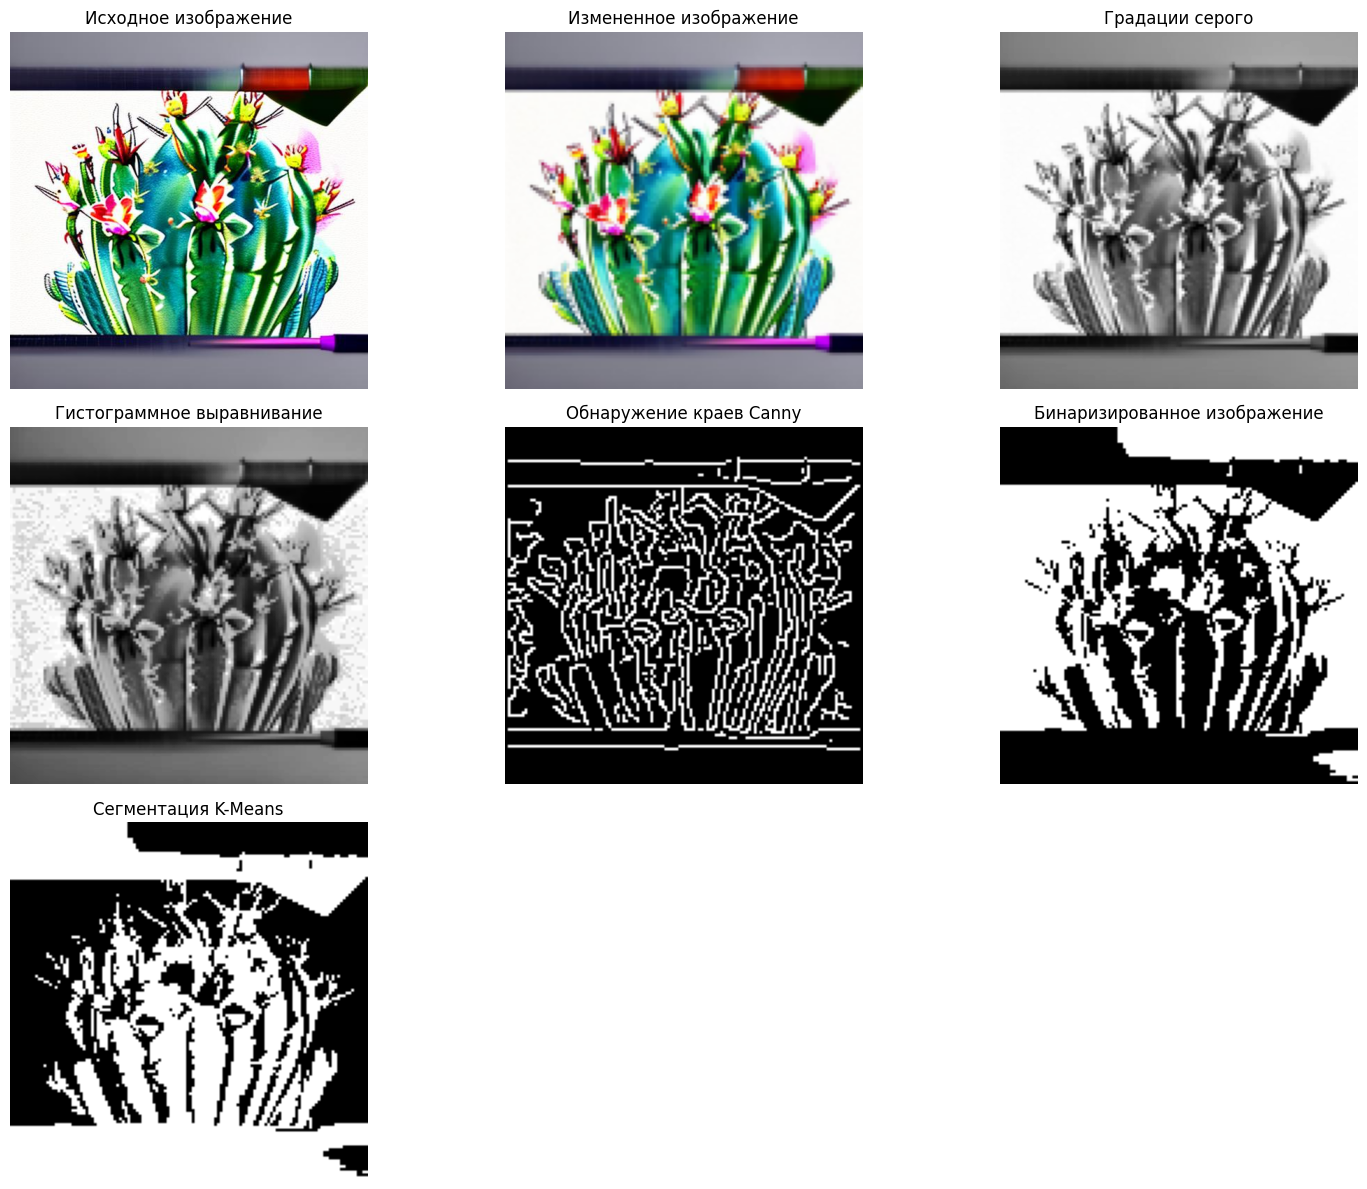

In [21]:
# Функция для отображения всех этапов обработки изображения
def display_all_steps(original, index):
    plt.figure(figsize=(15, 12))
    
    # Исходное изображение
    plt.subplot(3, 3, 1)
    plt.imshow(cv2.cvtColor(original[index], cv2.COLOR_BGR2RGB))
    plt.title('Исходное изображение')
    plt.axis('off')

    # Измененное изображение
    resized_image = cv2.resize(original[index], (128, 128), interpolation=cv2.INTER_AREA)
    plt.subplot(3, 3, 2)
    plt.imshow(cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB))
    plt.title('Измененное изображение')
    plt.axis('off')

    # Градации серого
    gray_image = cv2.cvtColor(resized_image, cv2.COLOR_BGR2GRAY)
    plt.subplot(3, 3, 3)
    plt.imshow(gray_image, cmap='gray')
    plt.title('Градации серого')
    plt.axis('off')

    # Гистограммное выравнивание
    hist_equalized = cv2.equalizeHist(gray_image)
    plt.subplot(3, 3, 4)
    plt.imshow(hist_equalized, cmap='gray')
    plt.title('Гистограммное выравнивание')
    plt.axis('off')

    # Обнаружение краев
    edges = canny(hist_equalized, sigma=1)
    plt.subplot(3, 3, 5)
    plt.imshow(edges, cmap='gray')
    plt.title('Обнаружение краев Canny')
    plt.axis('off')

    # Бинаризация изображения
    threshold = filters.threshold_otsu(hist_equalized)
    binary_image = hist_equalized > threshold
    plt.subplot(3, 3, 6)
    plt.imshow(binary_image, cmap='gray')
    plt.title('Бинаризированное изображение')
    plt.axis('off')

    # Сегментация с использованием K-Means
    pixels = hist_equalized.reshape(-1, 1)
    kmeans = KMeans(n_clusters=2, random_state=42).fit(pixels)
    segmented_kmeans = kmeans.labels_.reshape(hist_equalized.shape)
    plt.subplot(3, 3, 7)
    plt.imshow(segmented_kmeans, cmap='gray')
    plt.title('Сегментация K-Means')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# Пример отображения всех этапов для первого изображения
index = 0  
display_all_steps(images, index)

Применим глубокое обучение

Загрузим изображения и применим методы предобработки к ним после чего данные разделим на обучающий и тестовый наборы, преобразуем в формат TensorFlow, а также подготовим к обучению модели через преобразование в оттенки серого, перемешивание и группировку по батчам.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
import tensorflow as tf
import matplotlib.pyplot as plt
from matplotlib.image import imread
import os
from pathlib import Path
import numpy as np
import pandas as pd
import cv2

train_dir = "..\\static\\csv\\dataset"  
PIC_SIZE = 128
BATCH_SIZE = 8

def load_and_label_images_from_directory(directory, target_size=(PIC_SIZE, PIC_SIZE), allowed_labels=None):
    images = []
    labels = []
    
    if allowed_labels is None:
        allowed_labels = ['cactus', 'fern', 'rose', 'sunflower', 'tulip']
    
    for label in os.listdir(directory):
        if label in allowed_labels:
            label_folder = os.path.join(directory, label)
            if os.path.isdir(label_folder):
                for filename in os.listdir(label_folder):
                    img_path = os.path.join(label_folder, filename)
                    if img_path.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif')):
                        img = cv2.imread(img_path)
                        if img is not None:
                            img_resized = cv2.resize(img, target_size, interpolation=cv2.INTER_AREA)
                            images.append(img_resized)
                            labels.append(label)
                        else:
                            print(f"Ошибка загрузки изображения: {img_path}")
                    else:
                        print(f"Пропущен файл: {img_path}. Не является изображением.")
    
    return np.array(images), np.array(labels)

# Загружаем изображения и метки
train_images_raw, train_labels_raw = load_and_label_images_from_directory(train_dir)

# Обработка изображений
def preprocess_images(images):
    processed_images = []
    
    for image in images:
        # Нормализация изображения
        normalized_image = image.astype(np.float32) / 255.0
        processed_images.append(normalized_image)

    return np.array(processed_images)

# Применяем обработку к меню набору изображений
processed_images = preprocess_images(train_images_raw)

# Кодируем метки
label_encoder = LabelEncoder()
labels_encoded = label_encoder.fit_transform(train_labels_raw)
labels_categorical = tf.keras.utils.to_categorical(labels_encoded)

# Делим данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(processed_images, labels_categorical, test_size=0.2, random_state=42)

# Преобразуем в tf.data.Dataset
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
val_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))

# Функция для преобразования в оттенки серого
def convert_to_grayscale(image, label):
    image = tf.image.rgb_to_grayscale(image)
    return image, label

# Применяем преобразование к данным
train_ds = train_ds.map(convert_to_grayscale)
val_ds = val_ds.map(convert_to_grayscale)

# Перемешиваем и создаем батчи
train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Train dataset and validation dataset successfully prepared.")
print(f"Train shape: {X_train.shape}, Validation shape: {X_test.shape}")
print(f"Классы: {label_encoder.classes_}")

Train dataset and validation dataset successfully prepared.
Train shape: (1536, 128, 128, 3), Validation shape: (384, 128, 128, 3)
Классы: ['cactus' 'fern' 'rose' 'sunflower' 'tulip']


Настроим гиперпараметры 

Выполним поиск наилучшей модели с оптимизацией по валидационной точности и оценим её на тестовой выборке

In [23]:
from kerastuner import HyperModel, RandomSearch
from tensorflow.keras import layers
import tensorflow as tf

class ImageClassifier(HyperModel):
    def build(self, hp):
        model = tf.keras.Sequential([
            layers.Conv2D(hp.Int('filters_1', 32, 128, step=32), (3, 3), activation='relu', padding='same', kernel_initializer="he_normal", input_shape=(PIC_SIZE, PIC_SIZE, 3)),
            layers.MaxPooling2D(pool_size=(2, 2)),

            layers.Conv2D(hp.Int('filters_2', 32, 128, step=32), (3, 3), activation='relu', padding='same', kernel_initializer="he_normal"),
            layers.MaxPooling2D(pool_size=(2, 2)),

            layers.Conv2D(hp.Int('filters_3', 64, 256, step=64), (3, 3), activation='relu', padding='same', kernel_initializer="he_normal"),
            layers.MaxPooling2D(pool_size=(2, 2)),

            layers.GlobalAveragePooling2D(),
            layers.Dense(hp.Int('units', 64, 256, step=64), activation='relu', kernel_initializer="he_normal"),
            layers.Dropout(hp.Float('dropout', 0.1, 0.5, step=0.1)),
            layers.Dense(len(label_encoder.classes_), activation='softmax')
        ])

        model.compile(
            optimizer=tf.keras.optimizers.Adam(hp.Float('learning_rate', 1e-4, 1e-2, sampling='LOG')),
            loss='categorical_crossentropy',
            metrics=['accuracy']
        )

        return model

# Настройка Keras Tuner
tuner = RandomSearch(
    ImageClassifier(),
    objective='val_accuracy',
    max_trials=5,  # Уменьшено количество испытаний
    executions_per_trial=1,
    directory='ktune',
    project_name='image_classifier'
)

# Обучение модели с использованием Keras Tuner
tuner.search(X_train, y_train, epochs=5, validation_split=0.2)  # Уменьшено число эпох

# Получаем наилучшую модель
best_model = tuner.get_best_models(num_models=1)[0]

# Оценка модели на тестовой выборке
test_loss, test_acc = best_model.evaluate(X_test, y_test)
print(f"Тестовая точность: {test_acc * 100:.2f}%")

Reloading Tuner from ktune\image_classifier\tuner0.json


c:\Users\annal\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\annal\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\saving\saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - accuracy: 0.4886 - loss: 1.1627
Тестовая точность: 49.74%


In [24]:
# После получения наилучшей модели
best_model = tuner.get_best_models(num_models=1)[0]

# Вывод сводной информации о модели
best_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 96)   │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 128)    │       110,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 192)            │        12,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           965 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 200,645 (783.77 KB)

 Trainable params: 200,645 (783.77 KB)

 Non-trainable params: 0 (0.00 B)

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step


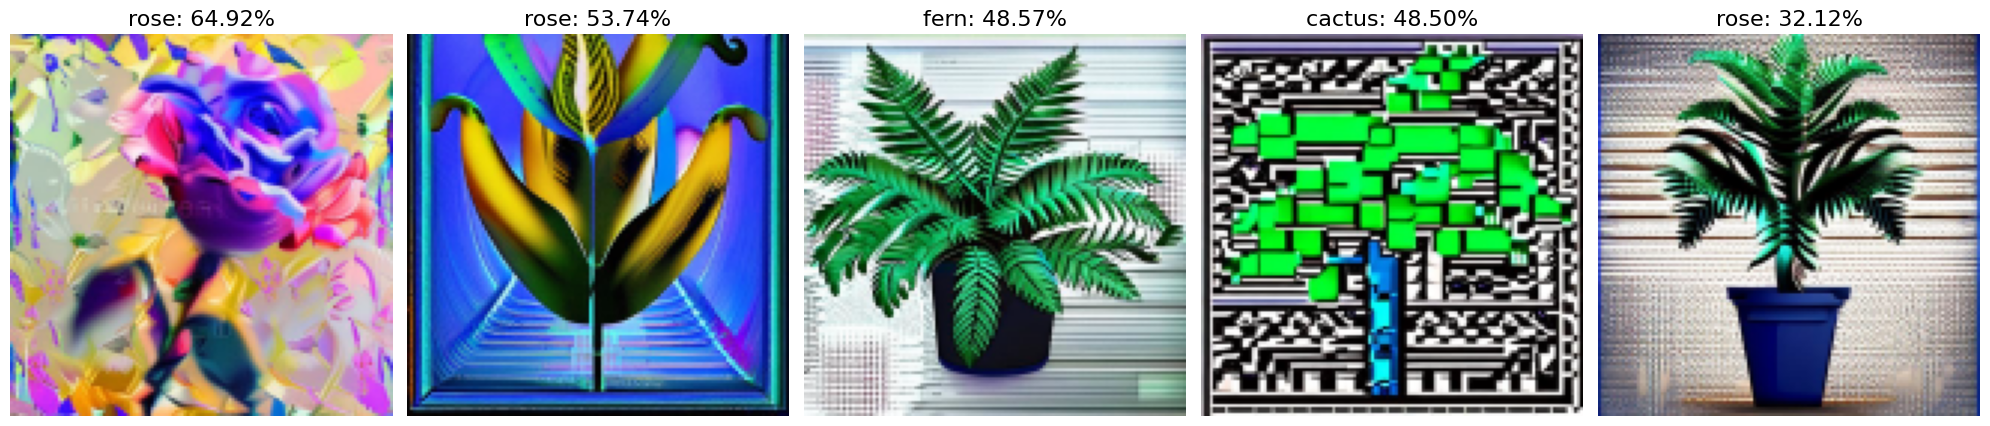

In [ ]:
# Делим данные на валидационную выборку - 20% от общего числа изображений
X_train, X_val, y_train, y_val = train_test_split(processed_images, labels_categorical, test_size=0.2, random_state=42)

tuner.search(X_train, y_train, epochs=20, validation_data=(X_val, y_val))

# Получаем наилучшую модель
best_model = tuner.get_best_models(num_models=1)[0]

# Получаем предсказания для всех изображений в валидационном наборе
y_pred = best_model.predict(X_val, batch_size=32)

# Берём только первые 5 предсказаний
prediction = y_pred[0:5]

# Собираем 5 изображений для визуализации
images_list = X_val[0:5]

# Визуализация 1 строки с 5 изображениями
plt.figure(figsize=(20, 5))  # Размер фигуры для 5 изображений

# Подготовка для хранения меток предсказаний
predict_label = []

for i in range(5):
    plt.subplot(1, 5, i + 1)  # 1 строка, 5 колонок
    image = images_list[i]  # Изображение из валидационного набора
    
    plt.imshow(image)  # Визуализация изображения в оригинальном цвете

    prob = prediction[i]  # Вероятности для каждого класса
    # Получаем индекс класса с максимальной вероятностью
    class_idx = np.argmax(prob)
    label = label_encoder.inverse_transform([class_idx])[0]  # Получаем метку класса
    confidence = prob[class_idx]  # Находим уверенность
    
    # Формирование текста заголовка
    predict_label.append(f"{label}: {confidence * 100:.2f}%")
    plt.title(predict_label[i], fontsize=16)
    plt.axis('off')

plt.tight_layout()
plt.show()

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 14s 345ms/step - accuracy: 0.5636 - loss: 1.0877 - val_accuracy: 0.6104 - val_loss: 1.0106
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 12s 319ms/step - accuracy: 0.5887 - loss: 0.9940 - val_accuracy: 0.6916 - val_loss: 0.8435
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 21s 556ms/step - accuracy: 0.6157 - loss: 0.9605 - val_accuracy: 0.7013 - val_loss: 0.8224
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 32s 325ms/step - accuracy: 0.6215 - loss: 0.8841 - val_accuracy: 0.6006 - val_loss: 0.9419
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 13s 331ms/step - accuracy: 0.6749 - loss: 0.8132 - val_accuracy: 0.7662 - val_loss: 0.6760
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 13s 336ms/step - accuracy: 0.7206 - loss: 0.7327 - val_accuracy: 0.7208 - val_loss: 0.7569
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 13s 334ms/step - accuracy: 0.7466 - loss: 0.6850 - val_accuracy: 0.7370 - val_loss: 0.7479
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 13s 334ms/step - accuracy: 0.7335 - loss: 0.7022 - val_accu

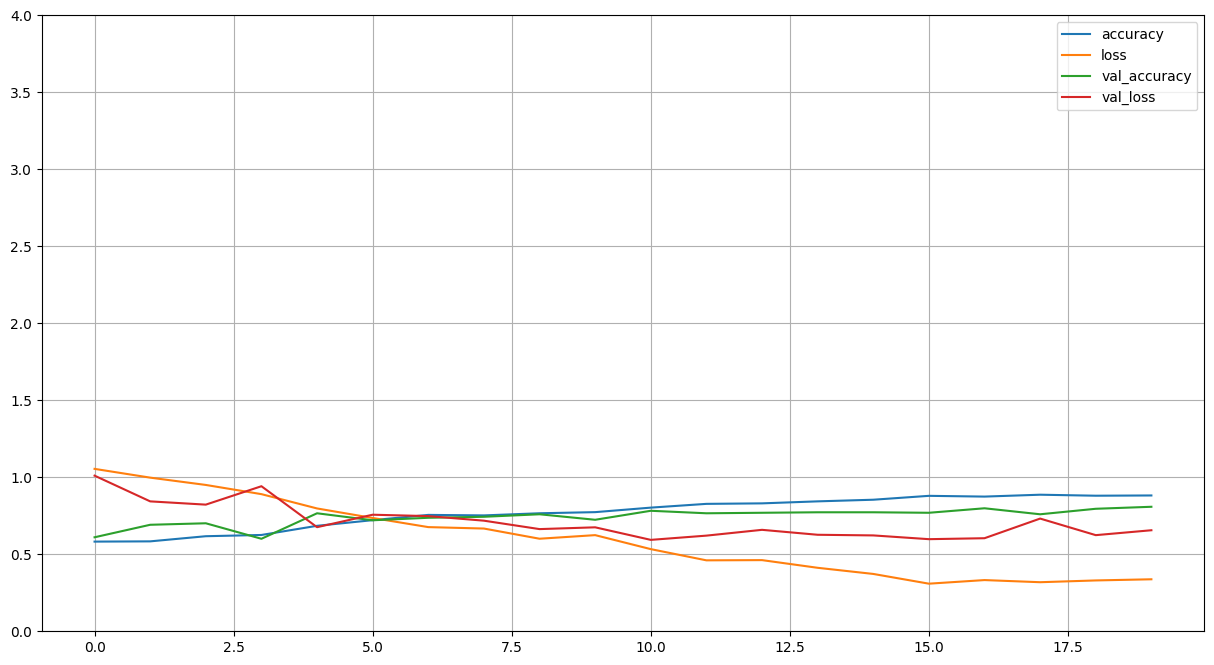

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - accuracy: 0.7635 - loss: 0.8039
Тестовая точность: 76.82%
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 91ms/step - accuracy: 0.9297 - loss: 0.2072
Train Loss: 0.2971, Train Accuracy: 0.9062
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.7635 - loss: 0.8039
Validation Loss: 0.7514, Validation Accuracy: 0.7682
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step


In [30]:
# Обучение модели с использованием Keras Tuner
tuner.search(X_train, y_train, epochs=20, validation_split=0.2)

# Получаем наилучшую модель
best_model = tuner.get_best_models(num_models=1)[0]

# Дообучение лучшей модели и получение истории обучения
history = best_model.fit(
    X_train, y_train,
    epochs=20,
    validation_split=0.2
)

# Визуализация истории обучения
import pandas as pd
import matplotlib.pyplot as plt

pd.DataFrame(history.history).plot(figsize=(15, 8))
plt.grid(True)
plt.gca().set_ylim(0, 4)
plt.show()

# Оценка модели на тестовой выборке
test_loss, test_acc = best_model.evaluate(X_test, y_test)
print(f"Тестовая точность: {test_acc * 100:.2f}%")

# Оценка модели на обучающем наборе
train_loss, train_acc = best_model.evaluate(X_train, y_train)
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")

# Оценка модели на валидационном наборе
val_loss, val_acc = best_model.evaluate(X_val, y_val)
print(f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.4f}")

# Предсказания на валидационном наборе
predictions = best_model.predict(X_val)

# Получение классов и уверенности
import numpy as np
predicted_classes = np.argmax(predictions, axis=1)
predicted_confidences = np.max(predictions, axis=1)  # Уверенность для каждого класса


Синяя линия (accuracy) показывает, что модель постепенно улучшает точность на обучающих данных и выходит на стабильный уровень. Зелёная линия (val_accuracy) растёт медленно и начинает колебаться, что может говорить о сложности валидационного набора или начальном переобучении. Оранжевая линия (loss) демонстрирует снижение ошибки на обучении, но при слишком слабом падении это может указывать на недостаточное обучение. Красная линия (val_loss) должна снижаться вместе с loss — если она растёт, значит, модель, вероятно, переобучается.